In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
df = pd.read_csv("winequality-red.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("First five rows:")
print(df.head())
print("\nDataset Shape:")
print(df.shape)

First five rows:
   fixed acidity  volatile acidity  citric acid  ...  sulphates  alcohol  quality
0            7.4              0.70         0.00  ...       0.56      9.4        5
1            7.8              0.88         0.00  ...       0.68      9.8        5
2            7.8              0.76         0.04  ...       0.65      9.8        5
3           11.2              0.28         0.56  ...       0.58      9.8        6
4            7.4              0.70         0.00  ...       0.56      9.4        5

[5 rows x 12 columns]

Dataset Shape:
(1599, 12)


In [ ]:
print("\n Colummn names:")
print(df.columns)


 Colummn names:
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')


In [ ]:
print("\n Missing Values")
print(df.isnull().sum())


 Missing Values
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [ ]:
x=df.drop('quality',axis=1)
y=df['quality']
normalizer=MInMaxScaler()
X_normalized=normalizer.fit_transform()
print(X_normalized)

Normalized Data (first 5 rows):
   fixed acidity  volatile acidity  citric acid  ...     pH  sulphates  alcohol
0          0.248             0.397         0.00  ...  0.606      0.138    0.154
1          0.283             0.521         0.00  ...  0.362      0.210    0.215
2          0.283             0.438         0.04  ...  0.409      0.192    0.215
3          0.584             0.110         0.56  ...  0.331      0.150    0.215
4          0.248             0.397         0.00  ...  0.606      0.138    0.154

[5 rows x 11 columns]

PCA Results (first 5 rows):
     PC1    PC2
0 -0.272 -0.195
1 -0.226 -0.259
2 -0.187 -0.180
3  0.422 -0.032
4 -0.272 -0.195

Original number of features: 11
Reduced number of features: 2

Variance retained by each component:
[0.3575 0.1943]
Total variance retained: 55.18 %


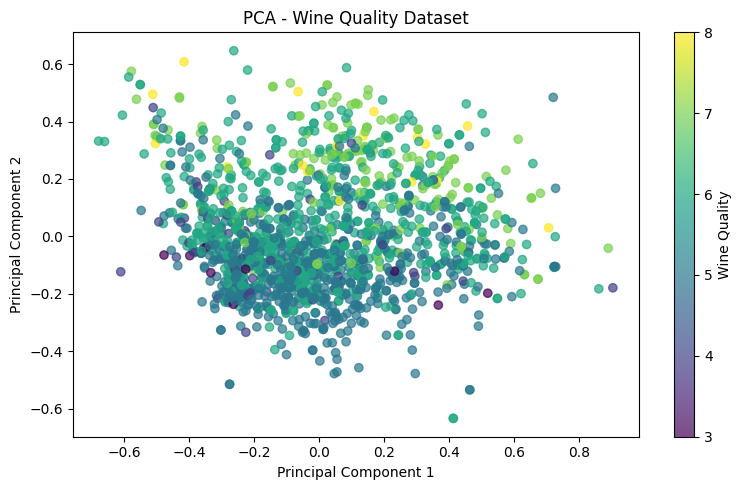


Minimum values:
fixed acidity           0.0
volatile acidity        0.0
citric acid             0.0
residual sugar          0.0
chlorides               0.0
free sulfur dioxide     0.0
total sulfur dioxide    0.0
density                 0.0
pH                      0.0
sulphates               0.0
alcohol                 0.0
dtype: float64

Maximum values:
fixed acidity           1.0
volatile acidity        1.0
citric acid             1.0
residual sugar          1.0
chlorides               1.0
free sulfur dioxide     1.0
total sulfur dioxide    1.0
density                 1.0
pH                      1.0
sulphates               1.0
alcohol                 1.0
dtype: float64

Explained variance ratio:
[0.35752287 0.1942533 ]


In [ ]:
# 1. Separate features and target
x = df.drop("quality", axis=1)
y = df["quality"]

# 2. Initialize MinMaxScaler
scaler = MinMaxScaler()

# 3. Normalize feature data
x_normalized = scaler.fit_transform(x)

# Convert normalized data into a DataFrame
normalized_df = pd.DataFrame(
    x_normalized,
    columns=x.columns,
    index=x.index
)

print("Normalized Data (first 5 rows):")
print(normalized_df.head().round(3))

# 4. Apply PCA with 2 components
pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_normalized)

# Convert PCA results into a DataFrame
pca_df = pd.DataFrame(
    x_pca,
    columns=["PC1", "PC2"],
    index=df.index
)

print("\nPCA Results (first 5 rows):")
print(pca_df.head().round(3))

# 5. Display feature reduction and explained variance
print("\nOriginal number of features:", x.shape[1])
print("Reduced number of features:", x_pca.shape[1])

print("\nVariance retained by each component:")
print(pca.explained_variance_ratio_.round(4))

print(
    "Total variance retained:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

# 6. Visualize PCA results
plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    x_pca[:, 0],
    x_pca[:, 1],
    c=y,
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Wine Quality Dataset")
plt.colorbar(scatter, label="Wine Quality")
plt.tight_layout()
plt.show()

# 7. Verify minimum and maximum normalized values
print("\nMinimum values:")
print(normalized_df.min())

print("\nMaximum values:")
print(normalized_df.max())

# 8. Display explained variance ratio
print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)